# 04 - Gray-coded QPSK, 16-QAM and 64-QAM
**Objective.** Build the mapper/demapper, verify Gray labelling and energy normalisation, and confirm the simulated uncoded BER against theory.

**Concept.** Square $M$-QAM = two independent Gray-coded PAM axes. The first $m=\log_2M/2$ bits select the in-phase level and the next $m$ bits the quadrature level. Levels are the odd integers $\pm1,\pm3,\dots$ scaled by $\sqrt{3/(2(M-1))}$ so that $E_s=1$. Gray labelling means nearest neighbours differ in **one** bit, so the most likely symbol error costs a single bit error.

$P_b \approx \dfrac{4}{k}\Bigl(1-\dfrac1{\sqrt M}\Bigr)Q\Bigl(\sqrt{\dfrac{3k}{M-1}\dfrac{E_b}{N_0}}\Bigr)$, $k=\log_2M$ (exact for QPSK; tight approximation for 16/64-QAM at moderate/high SNR).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional.modulation import Modem
from task1_conventional import channel as ch
from task1_conventional import plotting
from scipy.special import erfc
rng = np.random.default_rng(1)

## 1. Constellations

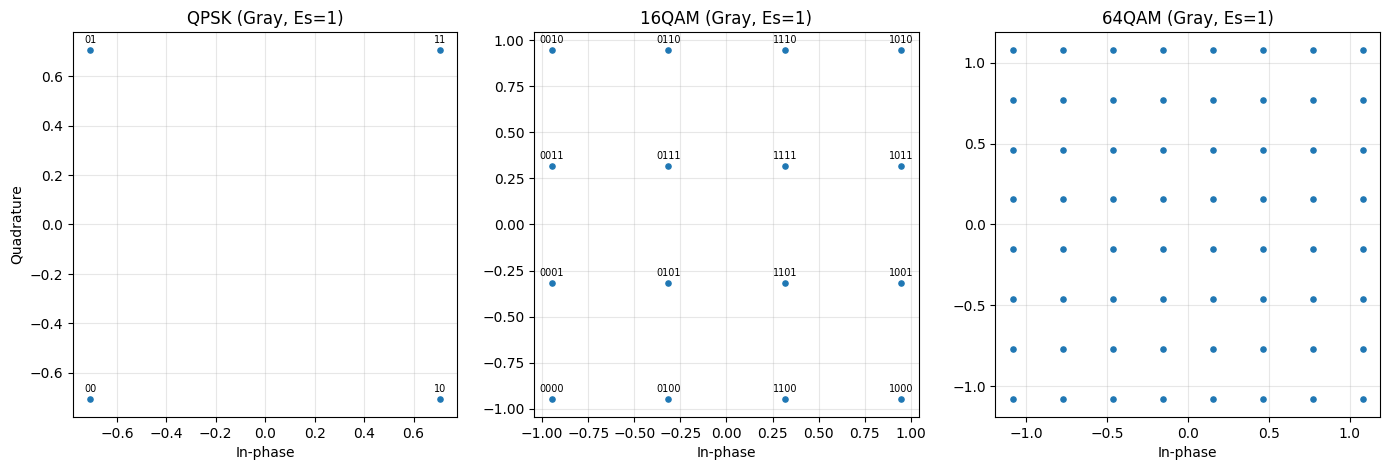

In [3]:
fig = plotting.plot_constellations(FIG / "constellations.png"); plt.show()

## 2. Verification checklist

In [4]:
rows = []
for n in ["BPSK", "QPSK", "16QAM", "64QAM"]:
    m = Modem(n); pts, tab = m.constellation()
    d = np.abs(pts[:, None] - pts[None, :]); np.fill_diagonal(d, np.inf); dmin = d.min()
    gray = all(np.sum(tab[i] != tab[j]) == 1 for i in range(m.M) for j in np.flatnonzero(np.isclose(d[i], dmin)))
    bits = rng.integers(0, 2, m.bps * 1000)
    rows.append(dict(modulation=n, bits_per_symbol=m.bps, points=m.M, Es=round(float(np.mean(abs(pts)**2)), 6),
                     d_min=round(float(dmin), 4), gray_neighbours_1bit=gray,
                     noiseless_roundtrip=bool(np.array_equal(m.demodulate_hard(m.modulate(bits)), bits))))
display(pd.DataFrame(rows))

,modulation,bits_per_symbol,points,Es,d_min,gray_neighbours_1bit,noiseless_roundtrip
0,BPSK,1,2,1.0,2.0000,True,True
1,QPSK,2,4,1.0,1.4142,True,True
2,16QAM,4,16,1.0,0.6325,True,True
3,64QAM,6,64,1.0,0.3086,True,True


### Incomplete bit groups
A bit stream whose length is not a multiple of $\log_2 M$ is **zero-padded**; the caller keeps the true length and drops the padding bits after demapping (done by the link in notebook 07).

In [5]:
m = Modem("16QAM"); bits = np.array([1, 0, 1, 1, 0, 1])        # 6 bits = 1.5 symbols
s = m.modulate(bits); print("symbols:", len(s), "| recovered:", m.demodulate_hard(s)[:len(bits)], "| padded bits added:", len(s) * m.bps - len(bits))

symbols: 2 | recovered: [1 0 1 1 0 1] | padded bits added: 2


## 3. Uncoded BER vs theory (AWGN)

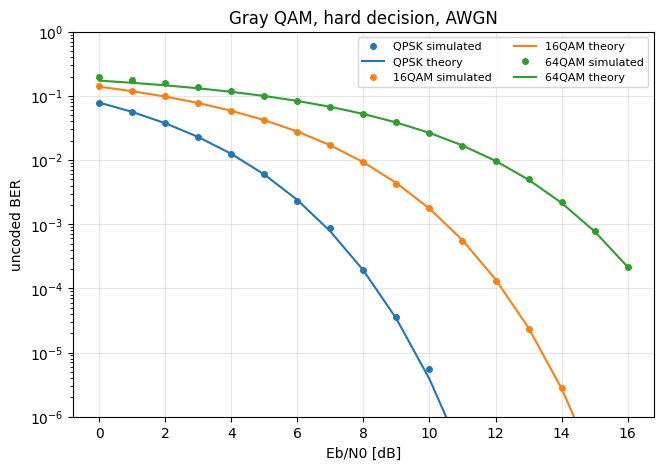

In [6]:
def ber_theory(mod, ebn0_db):
    k = Modem(mod).bps; M = 2 ** k; g = 10 ** (np.asarray(ebn0_db) / 10)
    Q = lambda x: 0.5 * erfc(x / np.sqrt(2))
    return 4 / k * (1 - 1 / np.sqrt(M)) * Q(np.sqrt(3 * k / (M - 1) * g))
fig, ax = plt.subplots(figsize=(7.5, 5)); eb = np.arange(0, 16.1, 1.0)
for n, c in zip(["QPSK", "16QAM", "64QAM"], ["C0", "C1", "C2"]):
    mo = Modem(n); sim = []
    for e in eb:
        es = ch.ebn0_to_esn0_db(e, mo.bps, 1.0); errs = bits = 0
        while errs < 200 and bits < 6_000_000:
            tx = rng.integers(0, 2, 600_000); y, _ = ch.awgn(mo.modulate(tx), es, rng)
            errs += np.count_nonzero(mo.demodulate_hard(y) != tx); bits += len(tx)
        sim.append(errs / bits)
    ax.semilogy(eb, sim, "o", color=c, ms=4, label=f"{n} simulated"); ax.semilogy(eb, ber_theory(n, eb), "-", color=c, label=f"{n} theory")
ax.set_ylim(1e-6, 1); ax.set_xlabel("Eb/N0 [dB]"); ax.set_ylabel("uncoded BER"); ax.legend(ncol=2, fontsize=8)
ax.set_title("Gray QAM, hard decision, AWGN"); fig.savefig(FIG / "uncoded_qam_ber.png", dpi=150); plt.show()

Simulation and theory agree (QPSK exactly; 16/64-QAM up to the nearest-neighbour approximation at low $E_b/N_0$). Higher-order modulation carries more bits per symbol but needs much more $E_b/N_0$ for the same BER - the trade-off AMC exploits.